In [4]:
import ast
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Loading Data
df = pd.read_csv('/content/data_jobs.xlsx - Sheet1.csv')

df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

In [5]:
df_India = df[df['job_country'] == 'India']

# **Explode Skills**

In [6]:
df_skills = df_India.explode('job_skills')

df_skills[['job_title', 'job_skills']]

,job_title,job_skills
99,Graduate Power BI Developer,sql
99,Graduate Power BI Developer,power bi
99,Graduate Power BI Developer,excel
105,Data Engineer 2,sql
105,Data Engineer 2,shell
...,...,...
32629,Staff Data Engineer - Full Stack,hadoop
32629,Staff Data Engineer - Full Stack,spark
32629,Staff Data Engineer - Full Stack,kafka
32629,Staff Data Engineer - Full Stack,angular


# **Count Skills per Job Title**

In [7]:
# Group by job_skills and job_title_short and count the number of occurrences
df_skills_count = df_skills.groupby(['job_skills', 'job_title_short']).size()

# Name the count column as count
df_skills_count = df_skills_count.reset_index(name='skill_count')

# Sort the values by skill_count in descending order
df_skills_count.sort_values(by='skill_count', ascending=False, inplace=True)

df_skills_count

,job_skills,job_title_short,skill_count
504,sql,Data Engineer,114
387,python,Data Engineer,99
487,spark,Data Engineer,84
388,python,Data Scientist,65
28,aws,Data Engineer,60
...,...,...,...
588,word,Software Engineer,1
25,atlassian,Senior Data Scientist,1
26,aurora,Data Engineer,1
9,alteryx,Data Engineer,1


In [8]:
job_titles = df_skills_count['job_title_short'].unique().tolist()

job_titles = sorted(job_titles[:3])

job_titles

['Data Analyst', 'Data Engineer', 'Data Scientist']

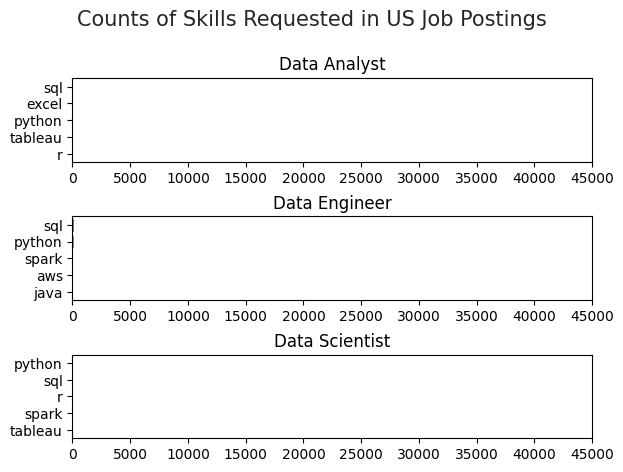

In [9]:
fig, ax = plt.subplots(len(job_titles), 1)

sns.set_theme(style='ticks')

for i, job_title in enumerate(job_titles):
    df_plot = df_skills_count[df_skills_count['job_title_short'] == job_title].head(5)[::-1]
    sns.barplot(data=df_plot, x='skill_count', y='job_skills', ax=ax[i], hue='skill_count', palette='dark:b_r')
    ax[i].set_title(job_title)
    ax[i].invert_yaxis()
    ax[i].set_ylabel('')
    ax[i].set_xlabel('')
    ax[i].get_legend().remove()
    ax[i].set_xlim(0, 45000) # make the scales the same

fig.suptitle('Counts of Skills Requested in US Job Postings', fontsize=15)
fig.tight_layout(h_pad=0.5) # fix the overlap
plt.show()

# **Convert Counts to Percentages**

In [10]:
# Use original df to get the count of job titles
df_job_title_count = df_India['job_title_short'].value_counts().reset_index(name='jobs_total')

df_job_title_count

,job_title_short,jobs_total
0,Data Engineer,170
1,Data Analyst,97
2,Data Scientist,93
3,Machine Learning Engineer,57
4,Senior Data Engineer,57
5,Software Engineer,45
6,Senior Data Scientist,33
7,Senior Data Analyst,27
8,Business Analyst,10


In [11]:
df_skills_perc = pd.merge(df_skills_count, df_job_title_count, on='job_title_short', how='left')

df_skills_perc['skill_percent'] = (df_skills_perc['skill_count'] / df_skills_perc['jobs_total']) * 100

df_skills_perc

,job_skills,job_title_short,skill_count,jobs_total,skill_percent
0,sql,Data Engineer,114,170,67.058824
1,python,Data Engineer,99,170,58.235294
2,spark,Data Engineer,84,170,49.411765
3,python,Data Scientist,65,93,69.892473
4,aws,Data Engineer,60,170,35.294118
...,...,...,...,...,...
589,word,Software Engineer,1,45,2.222222
590,atlassian,Senior Data Scientist,1,33,3.030303
591,aurora,Data Engineer,1,170,0.588235
592,alteryx,Data Engineer,1,170,0.588235


# **Plot Percentage Count**

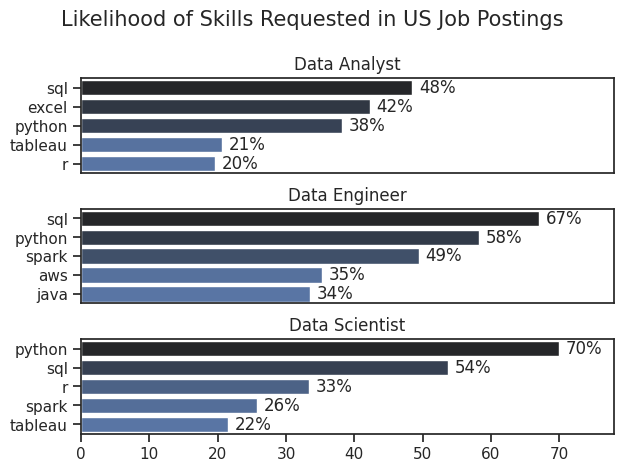

In [12]:
fig, ax = plt.subplots(len(job_titles), 1)


for i, job_title in enumerate(job_titles):
    df_plot = df_skills_perc[df_skills_perc['job_title_short'] == job_title].head(5)
    sns.barplot(data=df_plot, x='skill_percent', y='job_skills', ax=ax[i], hue='skill_count', palette='dark:b_r')
    ax[i].set_title(job_title)
    ax[i].set_ylabel('')
    ax[i].set_xlabel('')
    ax[i].get_legend().remove()
    ax[i].set_xlim(0, 78)
    # remove the x-axis tick labels for better readability
    if i != len(job_titles) - 1:
        ax[i].set_xticks([])

    # label the percentage on the bars
    for n, v in enumerate(df_plot['skill_percent']):
        ax[i].text(v + 1, n, f'{v:.0f}%', va='center')

fig.suptitle('Likelihood of Skills Requested in US Job Postings', fontsize=15)
fig.tight_layout(h_pad=.8)
plt.show()